# Customer Churn Prediction — Data Preparation, Model Development & Interpretation

## Purpose of this notebook

This notebook takes the cleaned Telco Customer Churn dataset from initial feature preparation through model development, evaluation, and interpretation.

It is designed to be both a reproducible project record and a learning document. Each major stage explains:

- **What** is being done.
- **Why** the step is needed.
- **How** the code performs it.
- **What we observed** and what decisions follow.

The notebook uses reusable functions and preprocessing components defined in `src/data/` and `src/models/`. The notebook is therefore the experiment and explanation layer; reusable implementation belongs in the Python modules.

### Workflow

1. Load and prepare the modelling dataset.
2. Create leakage-aware, group-aware train/test partitions.
3. Fit and verify preprocessing transformations.
4. Establish a Logistic Regression baseline.
5. Evaluate and tune a Random Forest.
6. Compare ranking performance and probability calibration.
7. Select a provisional model and classification threshold.
8. Evaluate once on the untouched test set.
9. Interpret the final model using permutation importance and SHAP.

> **Important evaluation rule:** the test set is reserved for final evaluation. Decisions about models and thresholds are made using the training set and its cross-validation predictions, not by repeatedly experimenting on the test set.

## 1. Environment and project setup

We first import the libraries and project functions used throughout the notebook. `PROJECT_ROOT` is derived from the notebook's expected location inside the `notebooks/` directory.

The autoreload extension is convenient during development: when a project module is saved, Jupyter can reload it so that updated functions are available without restarting the kernel.

Run this notebook from the project's `notebooks/` directory, with the `churn-env` kernel selected.

In [113]:
from pathlib import Path
import sys
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_data import load_data
from src.data.preprocess import (
    create_groups,
    split_data,
    preprocessor
)
import src.models.train as train

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Load the original dataset

We load the original workbook rather than a manually edited copy. This makes the preparation steps visible and reproducible.

The generic `load_data()` function is defined in `src/data/load_data.py`. It checks that the file exists, identifies the file format, and delegates reading to the appropriate pandas function.

The dataset contains 7,043 customer records and 33 columns.

In [114]:
from src.data.load_data import load_data

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco_customer_churn.xlsx"

df = load_data(DATA_PATH, sheet_name="Telco_Churn")

print(df.shape)

(7043, 33)


## 3. Clean `Total Charges`

### Why this column needs attention

During data understanding, `Total Charges` was found to have an object dtype rather than a consistent numeric dtype. Most entries were numeric, but 11 entries were blank strings. Those records had `Tenure Months == 0`.

A machine-learning model needs this feature in a numeric representation. We therefore:

1. Make a copy of the original DataFrame so that the raw data remains unchanged.
2. Convert `Total Charges` to numeric using `errors="coerce"`. Values that cannot be parsed become missing (`NaN`).
3. Identify rows where `Total Charges` is missing and tenure is zero.
4. Assign those rows a total charge of `0.0`.

### Assumption

A customer with zero months of tenure has not accumulated any tenure-based charges, so assigning zero total charges is a reasonable interpretation of these records. This is an explicit data-cleaning assumption, not a value directly observed in the source workbook.

We do not fill arbitrary missing values with zero. The replacement is limited to the specific pattern identified during data investigation.

In [115]:
df_clean = df.copy()

df_clean["Total Charges"] = pd.to_numeric(
    df_clean["Total Charges"],
    errors="coerce"
)

mask = (
    df_clean["Total Charges"].isna()
    & (df_clean["Tenure Months"] == 0)
)

df_clean.loc[mask, "Total Charges"] = 0.0

In [116]:
print("Missing Total Charges:", df_clean["Total Charges"].isna().sum())
print("Total Charges dtype:", df_clean["Total Charges"].dtype)

Missing Total Charges: 0
Total Charges dtype: float64


**Validation:** the conversion should leave `Total Charges` as a numeric column with no missing values. If missing values remain, investigate them rather than silently applying a broad imputation rule.

## 4. Define the modelling features and target

The target is `Churn Value`, where 1 represents churn and 0 represents no churn.

We exclude columns that should not be used as predictors for this modelling task:

- **Identifiers and row-count metadata:** `CustomerID`, `Count`.
- **Geographical fields:** country, state, city, postal code, coordinates and latitude/longitude. These are excluded from the initial model to avoid high-cardinality or redundant geographic information.
- **Target duplication:** `Churn Label` duplicates the target information.
- **Potentially unavailable or post-outcome fields:** `Churn Score`, `CLTV`, and `Churn Reason`. Their provenance and prediction-time availability are not established for this modelling setup; `Churn Reason` is explicitly an outcome-related field.

`X` contains the 19 selected predictors. `y` contains the binary target. Using `.copy()` creates independent DataFrame/Series objects for modelling.

In [117]:
excluded_columns = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Label",
    "Churn Score",
    "CLTV",
    "Churn Reason"
]

target_column = "Churn Value"

feature_columns = [
    column
    for column in df_clean.columns
    if column not in excluded_columns + [target_column]
]

X = df_clean[feature_columns].copy()
y = df_clean[target_column].copy()

In [118]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Target distribution:
Churn Value
0    5174
1    1869
Name: count, dtype: int64


### Target distribution and baseline context

The dataset contains 5,174 non-churners (73.46%) and 1,869 churners (26.54%). The classes are imbalanced, with roughly 2.77 non-churners for every churner.

A classifier that always predicts the majority class would achieve 73.46% accuracy while identifying none of the churners. Accuracy alone is therefore insufficient. We will also examine precision, recall, F1-score, ROC-AUC and Average Precision.

## 5. Create groups for repeated customer profiles

During data understanding, we found 40 repeated rows in the predictor matrix (`X.duplicated()`), involving 73 customers across 33 repeated feature-profile groups. These are not duplicate customer records: each row represents a distinct customer. Some identical predictor profiles have different churn labels.

Why group them? If customers with exactly the same predictor profile were randomly split between training and test sets, the model could encounter an identical feature profile in both partitions. This would make the evaluation less independent.

`create_groups(X)` assigns the same group identifier to customers with identical values across the 19 selected predictors. We use these identifiers to keep each repeated profile entirely within one partition.

This does **not** remove those customers or labels. It only constrains how records are allocated during splitting.

In [119]:
from src.data.preprocess import create_groups
groups = create_groups(X)

print("Total customers:", len(groups))
print("Unique groups:", groups.nunique())
print("Missing group IDs:", groups.isna().sum())

Total customers: 7043
Unique groups: 7003
Missing group IDs: 0


The expected result is 7,043 customer records and 7,003 unique profile groups. There are 33 groups containing more than one customer, involving 73 customers in total. No group identifier should be missing.

## 6. Create the train/test split

We use `StratifiedGroupKFold` through the reusable `split_data()` function in `src/data/preprocess.py`.

- **Group-aware:** identical predictor profiles cannot be split across training and test partitions.
- **Stratified:** the churn/non-churn proportions are kept reasonably similar across partitions.
- **Five folds:** one fold is selected as the test partition, giving an approximately 80:20 train/test split.
- **Reproducibility:** shuffling with `random_state=42` makes the partition repeatable.

The test set is held aside for final evaluation. All model selection, threshold analysis and cross-validation are performed using the training set.

In [120]:
from src.data.preprocess import split_data
X_train, X_test, y_train, y_test = split_data(
    X=X,
    y=y,
    groups=groups
)

In [121]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5633, 19)
Testing shape: (1410, 19)


### Verify class balance and group separation

We check two properties:

1. The churn proportions in training and test sets should be close to the overall class distribution.
2. The intersection of training and test group IDs must be empty. An overlap of zero confirms that no repeated predictor profile crosses the split boundary.

In [122]:
print("Training churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training churn distribution:
Churn Value
0    73.690751
1    26.309249
Name: proportion, dtype: float64

Testing churn distribution:
Churn Value
0    72.553191
1    27.446809
Name: proportion, dtype: float64


In [123]:
train_groups = set(groups.loc[X_train.index])
test_groups = set(groups.loc[X_test.index])

print("Overlapping groups:",
      len(train_groups.intersection(test_groups)))

Overlapping groups: 0


**Observed split:** 5,633 training records and 1,410 test records. The training churn proportion is approximately 26.31%, and the test churn proportion is approximately 27.45%. The group-overlap check returns zero. This supports retaining the split.

## 7. Build and inspect the preprocessing transformations

The raw training data contains 19 columns: 3 numerical and 16 categorical features.

The preprocessing object in `src/data/preprocess.py` is a `ColumnTransformer` containing two pipelines:

- **Numerical pipeline:** `StandardScaler` standardizes `Tenure Months`, `Monthly Charges` and `Total Charges`.
- **Categorical pipeline:** `OneHotEncoder(handle_unknown="ignore")` converts categorical values into binary indicator columns.

### Why these transformations?

Many machine-learning algorithms operate on numeric arrays, so categorical strings must be encoded. One-hot encoding avoids imposing an artificial numeric order on categories.

Standardization puts numerical features on comparable scales. It is especially useful for models such as Logistic Regression, where feature scale can affect optimization and regularization. Random Forests generally do not require scaling, but using a consistent preprocessing pipeline makes it straightforward to compare both model families.

The encoder uses `handle_unknown="ignore"` so that an unseen category at inference time does not cause the prediction pipeline to fail. The encoder and scaler must be fitted only on training data to prevent information from the test set influencing preprocessing.

### Fit transformations on training data only

`fit_transform()` learns the numerical means and standard deviations and the categorical levels from `X_train`, then transforms the training data.

This explicit inspection is useful for understanding the transformation. During cross-validation and final model fitting, the same preprocessing steps are also embedded inside the model pipeline so that each fold learns its transformations from that fold's training partition only.

In [124]:
from src.data.preprocess import preprocessor
X_train_processed = preprocessor.fit_transform(X_train)

In [125]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOutput data type:", type(X_train_processed))
print("Matrix data type:", X_train_processed.dtype)

Original training shape: (5633, 19)
Processed training shape: (5633, 46)

Output data type: <class 'numpy.ndarray'>
Matrix data type: float64


The training data changes from 19 raw columns to 46 transformed columns: 3 scaled numerical columns and 43 one-hot encoded columns.

The output is a NumPy array with `float64` values. This is expected because the transformed numerical and indicator features are represented in a common numeric matrix.

In [126]:
feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))

for name in feature_names:
    print(name)

Number of transformed features: 46
num__Tenure Months
num__Monthly Charges
num__Total Charges
cat__Gender_Female
cat__Gender_Male
cat__Senior Citizen_No
cat__Senior Citizen_Yes
cat__Partner_No
cat__Partner_Yes
cat__Dependents_No
cat__Dependents_Yes
cat__Phone Service_No
cat__Phone Service_Yes
cat__Multiple Lines_No
cat__Multiple Lines_No phone service
cat__Multiple Lines_Yes
cat__Internet Service_DSL
cat__Internet Service_Fiber optic
cat__Internet Service_No
cat__Online Security_No
cat__Online Security_No internet service
cat__Online Security_Yes
cat__Online Backup_No
cat__Online Backup_No internet service
cat__Online Backup_Yes
cat__Device Protection_No
cat__Device Protection_No internet service
cat__Device Protection_Yes
cat__Tech Support_No
cat__Tech Support_No internet service
cat__Tech Support_Yes
cat__Streaming TV_No
cat__Streaming TV_No internet service
cat__Streaming TV_Yes
cat__Streaming Movies_No
cat__Streaming Movies_No internet service
cat__Streaming Movies_Yes
cat__Contrac

### Transform the test data

For test data, we call `transform()` rather than `fit_transform()`. This applies the means, standard deviations and category mapping learned from the training set. The test set must not influence those learned preprocessing parameters.

Both transformed matrices should have the same number and ordering of columns.

In [127]:
X_test_processed = preprocessor.transform(X_test)

In [128]:
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5633, 46)
Processed testing shape: (1410, 46)


### Inspect what the fitted transformer learned

The numerical scaler's `mean_` values are learned from the training set. The encoder's `categories_` lists show the category levels it learned for each categorical feature.

The categories `No phone service` and `No internet service` are valid dataset categories, not missing values. They must remain distinct categories during encoding.

In [129]:
print("Scaler means:")
print(preprocessor.named_transformers_["num"]
      .named_steps["scaler"].mean_)

print("\nEncoder categories:")
print(preprocessor.named_transformers_["cat"]
      .named_steps["encoder"].categories_)

Scaler means:
[  32.38771525   64.74838452 2279.89881058]

Encoder categories:
[array(['Female', 'Male'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'Yes'], dtype=object), array(['No', 'No phone service', 'Yes'], dtype=object), array(['DSL', 'Fiber optic', 'No'], dtype=object), array(['No', 'No internet service', 'Yes'], dtype=object), array(['No', 'No internet service', 'Yes'], dtype=object), array(['No', 'No internet service', 'Yes'], dtype=object), array(['No', 'No internet service', 'Yes'], dtype=object), array(['No', 'No internet service', 'Yes'], dtype=object), array(['No', 'No internet service', 'Yes'], dtype=object), array(['Month-to-month', 'One year', 'Two year'], dtype=object), array(['No', 'Yes'], dtype=object), array(['Bank transfer (automatic)', 'Credit card (automatic)',
       'Electronic check', 'Mailed check'], dtype=object)]


## 8. Logistic Regression baseline

We begin with Logistic Regression as an interpretable linear baseline. The model is created using `build_model_pipeline()` in `src/models/train.py`. The pipeline combines preprocessing and classification into one estimator.

Keeping preprocessing inside the pipeline is essential for cross-validation: each fold fits its own scaler and encoder using only that fold's training records. This prevents preprocessing leakage between folds.

We evaluate using five-fold `StratifiedGroupKFold` cross-validation, preserving both class proportions and repeated-profile group integrity.

In [130]:
from src.models.train import evaluate_model_cv

groups_train = groups.loc[X_train.index]

cv_results = evaluate_model_cv(
    X_train=X_train,
    y_train=y_train,
    groups_train=groups_train
)

In [131]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]

    print(f"{metric.upper()}:")
    print(f"  Fold scores: {scores}")
    print(f"  Mean: {scores.mean():.4f}")
    print(f"  Standard deviation: {scores.std():.4f}")
    print()

ACCURACY:
  Fold scores: [0.81576616 0.80676759 0.80871886 0.81616341 0.80990274]
  Mean: 0.8115
  Standard deviation: 0.0038

PRECISION:
  Fold scores: [0.63878327 0.64258555 0.67896679 0.67578125 0.66798419]
  Mean: 0.6608
  Standard deviation: 0.0169

RECALL:
  Fold scores: [0.59786477 0.57876712 0.58974359 0.58249158 0.56333333]
  Mean: 0.5824
  Standard deviation: 0.0116

F1:
  Fold scores: [0.61764706 0.60900901 0.63121784 0.62567812 0.61121157]
  Mean: 0.6190
  Standard deviation: 0.0084

ROC_AUC:
  Fold scores: [0.84355905 0.85129115 0.85008131 0.86943825 0.86790213]
  Mean: 0.8565
  Standard deviation: 0.0103



### Logistic Regression cross-validation results

The mean scores were approximately:

| Metric | Mean |
|---|---:|
| Accuracy | 0.8115 |
| Precision | 0.6608 |
| Recall | 0.5824 |
| F1-score | 0.6190 |
| ROC-AUC | 0.8565 |

The standard deviations across folds were small, indicating reasonably consistent results across these partitions. Recall is lower than precision, so the baseline misses a portion of actual churners. This motivates comparing another model family.

### Out-of-fold probabilities and threshold analysis

For threshold analysis, we need probabilities for training customers who were not used to fit the model that generated each probability.

`generate_oof_probabilities()` uses grouped cross-validation to produce one out-of-fold prediction per training record. These predictions are more appropriate for threshold analysis than predictions made on the same records used to fit the model.

A threshold converts a probability into a class label. Lowering the threshold generally increases recall and decreases precision; raising it generally increases precision and decreases recall. The appropriate trade-off depends on the costs and capacity of a retention campaign.

In [132]:
from src.models.train import generate_oof_probabilities

y_proba_oof = generate_oof_probabilities(
    X_train=X_train,
    y_train=y_train,
    groups_train=groups_train
)

In [133]:
print(y_proba_oof.shape)

(5633, 2)


In [134]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (
        y_proba_oof[:, 1] >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, y_pred_threshold),
        "Recall": recall_score(y_train, y_pred_threshold),
        "F1": f1_score(y_train, y_pred_threshold)
    })

lr_threshold_df = pd.DataFrame(threshold_results)
lr_threshold_df

,Threshold,Precision,Recall,F1
0,0.2,0.486822,0.872470,0.624940
1,0.3,0.549881,0.777328,0.644115
2,0.4,0.607831,0.680837,0.642266
3,0.5,0.660796,0.582321,0.619082
4,0.6,0.717249,0.443320,0.547957
5,0.7,0.753333,0.228745,0.350932
6,0.8,0.841270,0.035762,0.068608


**Logistic Regression observation:** among the tested thresholds, 0.3 gave the highest F1-score (approximately 0.6441). This is a training-set development result, not a final business threshold. We will compare it with the Random Forest before making a provisional model/threshold decision.

## 9. Random Forest baseline

Random Forest is a tree-ensemble model that can learn nonlinear relationships and feature interactions. Unlike Logistic Regression, it does not require numerical standardization for its split decisions, but we retain the same pipeline structure so the full workflow remains consistent.

We first evaluate the untuned Random Forest using the same grouped five-fold cross-validation and metrics used for Logistic Regression. This makes the initial comparison fair in terms of data partitions and evaluation procedure.

In [135]:
importlib.reload(train)

<module 'src.models.train' from 'd:\\ML_Projects\\Project1\\customer-churn-intelligence\\src\\models\\train.py'>

In [136]:
from src.models.train import evaluate_random_forest_cv

rf_cv_results = evaluate_random_forest_cv(
    X_train=X_train,
    y_train=y_train,
    groups_train=groups_train
)

In [137]:
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = rf_cv_results[f"test_{metric}"]

    print(f"{metric.upper()}:")
    print(f"  Fold scores: {scores}")
    print(f"  Mean: {scores.mean():.4f}")
    print(f"  Standard deviation: {scores.std():.4f}")
    print()

ACCURACY:
  Fold scores: [0.80336581 0.79786287 0.78380783 0.80106572 0.79310345]
  Mean: 0.7958
  Standard deviation: 0.0069

PRECISION:
  Fold scores: [0.63111111 0.6419214  0.64935065 0.65665236 0.63636364]
  Mean: 0.6431
  Standard deviation: 0.0091

RECALL:
  Fold scores: [0.50533808 0.50342466 0.48076923 0.51515152 0.51333333]
  Mean: 0.5036
  Standard deviation: 0.0123

F1:
  Fold scores: [0.56126482 0.56429942 0.55248619 0.57735849 0.56826568]
  Mean: 0.5647
  Standard deviation: 0.0082

ROC_AUC:
  Fold scores: [0.83107206 0.83816536 0.83195379 0.84283527 0.8475712 ]
  Mean: 0.8383
  Standard deviation: 0.0063



**Baseline comparison:** the untuned Random Forest achieved lower mean ROC-AUC (approximately 0.8383) and F1-score (approximately 0.5647) than Logistic Regression (ROC-AUC approximately 0.8565; F1 approximately 0.6190). This is a reason to investigate tuning, not evidence that Random Forest is inherently inferior. Hyperparameters can materially affect tree-ensemble performance.

## 10. Random Forest hyperparameter tuning

We use `RandomizedSearchCV` with five-fold `StratifiedGroupKFold` cross-validation. Randomized search samples combinations from the parameter distributions rather than exhaustively evaluating every possible combination.

The search optimizes ROC-AUC, which evaluates how well the model ranks churners above non-churners across classification thresholds. This is useful at the model-selection stage because it is not tied to a single threshold.

The search is configured for 50 sampled parameter combinations. The group labels are passed to `.fit()` so the cross-validation folds respect the repeated-profile grouping.

In [138]:
rf_search = train.tune_random_forest(
    X_train=X_train,
    y_train=y_train,
    groups_train=groups_train,
    n_iter=50,
    n_splits=5,
    random_state=42
)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [139]:
print("Best CV ROC-AUC:", rf_search.best_score_)
print("\nBest Hyperparameters:")
print(rf_search.best_params_)

Best CV ROC-AUC: 0.8602143176281867

Best Hyperparameters:
{'classifier__class_weight': 'balanced_subsample', 'classifier__max_depth': 30, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 9, 'classifier__min_samples_split': 6, 'classifier__n_estimators': 424}


### Inspect the leading configurations

The table below shows the strongest configurations according to mean validation ROC-AUC. Comparing training and validation scores can help identify overfitting: a large training-validation gap suggests the model fits the training folds substantially better than unseen validation folds.

In [140]:
cv_results = pd.DataFrame(rf_search.cv_results_)

cv_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "params"
    ]
].sort_values("rank_test_score").head(10)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
28,1,0.860214,0.007823,0.911016,{'classifier__class_weight': 'balanced_subsamp...
14,2,0.860050,0.007701,0.910920,{'classifier__class_weight': 'balanced_subsamp...
39,3,0.859736,0.007416,0.913940,"{'classifier__class_weight': 'balanced', 'clas..."
45,4,0.859706,0.007428,0.914034,"{'classifier__class_weight': 'balanced', 'clas..."
13,5,0.859668,0.007398,0.914349,{'classifier__class_weight': 'balanced_subsamp...
1,6,0.859536,0.007729,0.911531,{'classifier__class_weight': 'balanced_subsamp...
4,7,0.859388,0.007480,0.914569,"{'classifier__class_weight': 'balanced', 'clas..."
2,8,0.859249,0.007704,0.915507,"{'classifier__class_weight': 'balanced', 'clas..."
46,9,0.859206,0.007137,0.914548,"{'classifier__class_weight': 'balanced', 'clas..."
21,10,0.859206,0.007274,0.914313,"{'classifier__class_weight': 'balanced', 'clas..."


**Selected configuration:** the best mean CV ROC-AUC was approximately 0.8602. The selected parameters were:

- `n_estimators`: 424
- `max_depth`: 30
- `max_features`: `log2`
- `min_samples_leaf`: 9
- `min_samples_split`: 6
- `class_weight`: `balanced_subsample`

The best estimator is refitted on the full training set by `RandomizedSearchCV` because its default `refit=True`. We still use cross-validation predictions for development metrics and keep the test set untouched.

In [141]:
print("Best CV ROC-AUC:", rf_search.best_score_)

print("\nBest Hyperparameters:")
for parameter, value in rf_search.best_params_.items():
    print(f"{parameter}: {value}")

Best CV ROC-AUC: 0.8602143176281867

Best Hyperparameters:
classifier__class_weight: balanced_subsample
classifier__max_depth: 30
classifier__max_features: log2
classifier__min_samples_leaf: 9
classifier__min_samples_split: 6
classifier__n_estimators: 424


### Re-evaluate the tuned Random Forest

We evaluate the selected hyperparameter configuration with the same five-fold grouped cross-validation and metrics. This gives us a fuller view of its classification behaviour at the default 0.5 threshold, in addition to the ROC-AUC score used during search.

In [142]:
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedGroupKFold

best_rf = rf_search.best_estimator_

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

tuned_rf_results = cross_validate(
    estimator=best_rf,
    X=X_train,
    y=y_train,
    cv=cv,
    groups=groups_train,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

In [143]:
for metric in scoring:
    scores = tuned_rf_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

accuracy: 0.7779 ± 0.0060
precision: 0.5564 ± 0.0167
recall: 0.7694 ± 0.0062
f1: 0.6456 ± 0.0110
roc_auc: 0.8602 ± 0.0078


**Tuned Random Forest CV results:**

| Metric | Mean ± standard deviation |
|---|---:|
| Accuracy | 0.7779 ± 0.0060 |
| Precision | 0.5564 ± 0.0167 |
| Recall | 0.7694 ± 0.0062 |
| F1-score | 0.6456 ± 0.0110 |
| ROC-AUC | 0.8602 ± 0.0078 |

The tuned Random Forest has higher recall and F1-score than the Logistic Regression baseline at threshold 0.5, while its accuracy and precision are lower. It identifies a larger fraction of churners, at the cost of flagging more non-churners.

### Tuned Random Forest out-of-fold probabilities and threshold analysis

We again generate out-of-fold probabilities on the training set. We then evaluate precision, recall and F1 at a range of thresholds.

This step is important because a probability model and a classification decision are not the same thing. The model estimates a probability; the threshold expresses how that probability is converted into an action or label.

In [144]:
from sklearn.model_selection import cross_val_predict

y_proba_rf_oof = cross_val_predict(
    estimator=rf_search.best_estimator_,
    X=X_train,
    y=y_train,
    cv=cv,
    groups=groups_train,
    method="predict_proba",
    n_jobs=-1
)

In [145]:
y_proba_rf_oof.shape

(5633, 2)

In [146]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results = []

for threshold in thresholds:

    y_pred = (y_proba_rf_oof[:, 1] >= threshold).astype(int)

    precision = precision_score(y_train, y_pred)
    recall = recall_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

rf_threshold_df = pd.DataFrame(threshold_results)

rf_threshold_df

,Threshold,Precision,Recall,F1
0,0.2,0.388859,0.970310,0.555212
1,0.3,0.446330,0.923077,0.601715
2,0.4,0.499606,0.854926,0.630662
3,0.5,0.556369,0.769231,0.645709
4,0.6,0.617978,0.668016,0.642023
5,0.7,0.684755,0.536437,0.601589
6,0.8,0.752560,0.297571,0.426499


**Tuned Random Forest threshold results:**

| Threshold | Precision | Recall | F1 |
|---:|---:|---:|---:|
| 0.2 | 0.3889 | 0.9703 | 0.5552 |
| 0.3 | 0.4463 | 0.9231 | 0.6017 |
| 0.4 | 0.4996 | 0.8549 | 0.6307 |
| **0.5** | **0.5564** | **0.7692** | **0.6457** |
| 0.6 | 0.6180 | 0.6680 | 0.6420 |
| 0.7 | 0.6848 | 0.5364 | 0.6016 |
| 0.8 | 0.7526 | 0.2976 | 0.4265 |

Among the thresholds tested, 0.5 gives the highest F1-score for the tuned Random Forest. A lower threshold catches more churners but creates more false positives; a higher threshold reduces false positives but misses more churners.

## 11. Ranking performance: Precision–Recall curve and Average Precision

The precision–recall curve shows the trade-off between precision and recall as the classification threshold varies. It is especially informative when the positive class (churn) is the minority class.

Average Precision (AP) summarizes the precision–recall curve. Higher AP indicates better ranking of positive cases across recall levels. We compare Logistic Regression and the tuned Random Forest using their out-of-fold probabilities.

In [147]:
from sklearn.metrics import precision_recall_curve

# Logistic Regression
lr_precision, lr_recall, lr_thresholds = precision_recall_curve(
    y_train,
    y_proba_oof[:, 1]
)

# Tuned Random Forest
rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_train,
    y_proba_rf_oof[:, 1]
)

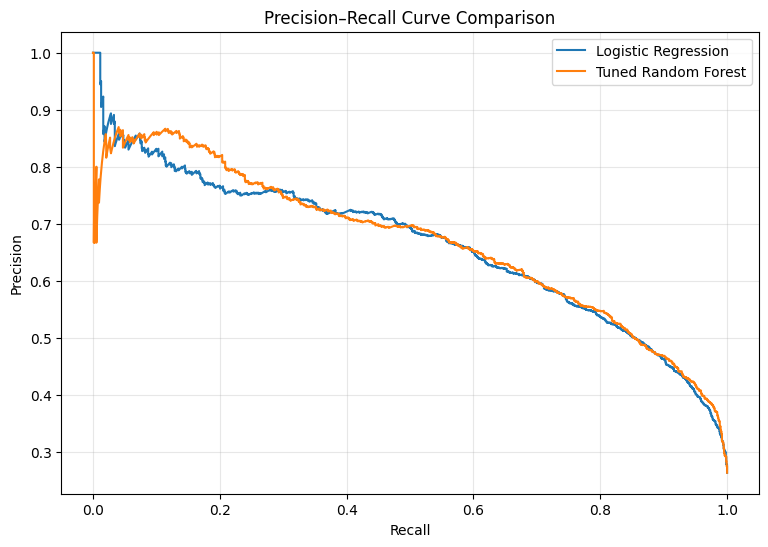

In [148]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    lr_recall,
    lr_precision,
    label="Logistic Regression"
)

plt.plot(
    rf_recall,
    rf_precision,
    label="Tuned Random Forest"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [149]:
from sklearn.metrics import average_precision_score

lr_ap = average_precision_score(
    y_train,
    y_proba_oof[:, 1]
)

rf_ap = average_precision_score(
    y_train,
    y_proba_rf_oof[:, 1]
)

print("Logistic Regression AP:", round(lr_ap, 4))
print("Tuned Random Forest AP:", round(rf_ap, 4))

Logistic Regression AP: 0.6622
Tuned Random Forest AP: 0.6676


**Observed AP:** Logistic Regression achieved approximately 0.6622, while the tuned Random Forest achieved approximately 0.6676. The Random Forest has a modest advantage in ranking churners, consistent with its slightly higher ROC-AUC.

## 12. Probability calibration

A model can rank customers well but still produce probabilities that do not match observed frequencies. Calibration asks whether, among customers assigned a probability near (for example) 0.70, approximately 70% actually churn.

We assess calibration using:

- **Brier score:** mean squared error between predicted probabilities and binary outcomes; lower is better.
- **Reliability curve:** compares mean predicted probability in bins with the observed positive fraction in those bins.

We use out-of-fold probabilities for these assessments so each training customer's probability is generated by a model that did not train on that customer.

In [150]:
from sklearn.metrics import brier_score_loss

lr_brier = brier_score_loss(
    y_train,
    y_proba_oof[:, 1]
)

rf_brier = brier_score_loss(
    y_train,
    y_proba_rf_oof[:, 1]
)

print("Logistic Regression Brier Score:", round(lr_brier, 4))
print("Tuned Random Forest Brier Score:", round(rf_brier, 4))

Logistic Regression Brier Score: 0.1308
Tuned Random Forest Brier Score: 0.1486


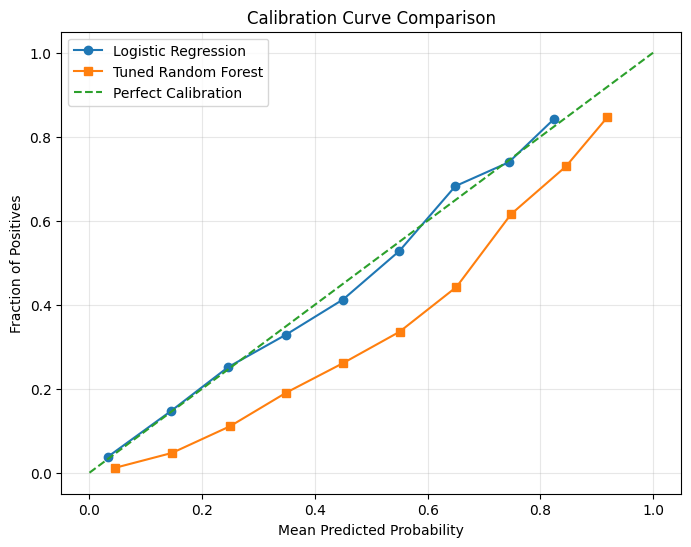

In [151]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

lr_fraction, lr_mean = calibration_curve(
    y_train,
    y_proba_oof[:, 1],
    n_bins=10,
    strategy="uniform"
)

rf_fraction, rf_mean = calibration_curve(
    y_train,
    y_proba_rf_oof[:, 1],
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    lr_mean,
    lr_fraction,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    rf_mean,
    rf_fraction,
    marker="s",
    label="Tuned Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

The initial out-of-fold Brier scores were approximately 0.1308 for Logistic Regression and 0.1486 for the tuned Random Forest. Lower is better, so Logistic Regression's probabilities were better calibrated by this measure, even though the tuned Random Forest had slightly stronger ranking performance.

### Group-aware calibration folds

We investigate sigmoid calibration for the Random Forest using `CalibratedClassifierCV`. Calibration itself must be fitted without allowing a record's target to influence the model that generates its calibration prediction.

We construct inner calibration folds using `StratifiedGroupKFold`, again keeping identical predictor profiles together. The following check confirms that the training and calibration groups do not overlap within any fold.

In [152]:
from sklearn.model_selection import StratifiedGroupKFold

calibration_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

calibration_splits = list(
    calibration_cv.split(
        X_train,
        y_train,
        groups=groups_train
    )
)

In [153]:
for fold, (train_idx, calibration_idx) in enumerate(calibration_splits, start=1):

    train_groups = set(groups_train.iloc[train_idx])
    calibration_groups = set(groups_train.iloc[calibration_idx])

    print(
        f"Fold {fold}: "
        f"Group overlap = {len(train_groups & calibration_groups)}"
    )

Fold 1: Group overlap = 0
Fold 2: Group overlap = 0
Fold 3: Group overlap = 0
Fold 4: Group overlap = 0
Fold 5: Group overlap = 0


### Nested out-of-fold calibration evaluation

A calibration model fitted on all training records and then scored on those same records would produce optimistic results. We therefore use an outer grouped cross-validation loop.

For each outer fold:
1. Hold out the outer validation fold.
2. Build inner grouped folds using only the outer training partition.
3. Fit the calibrated Random Forest on the outer training partition.
4. Predict probabilities for the untouched outer validation partition.

Combining these predictions gives one out-of-fold calibrated probability per training record. This is the appropriate probability set for comparing calibration.

In [154]:
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

outer_splits = list(
    outer_cv.split(
        X_train,
        y_train,
        groups=groups_train
    )
)

In [155]:
from sklearn.base import clone

y_proba_rf_calibrated_oof = np.zeros(len(y_train))

for fold, (train_idx, val_idx) in enumerate(outer_splits, start=1):

    X_outer_train = X_train.iloc[train_idx]
    X_outer_val = X_train.iloc[val_idx]

    y_outer_train = y_train.iloc[train_idx]
    groups_outer_train = groups_train.iloc[train_idx]

    # Generate inner, group-aware calibration folds
    inner_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    inner_splits = list(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=groups_outer_train
        )
    )

    # Build calibrated model
    calibrated_model = train.build_calibrated_rf_pipeline(
        calibration_splits=inner_splits
    )

    # Fit only on outer training data
    calibrated_model.fit(
        X_outer_train,
        y_outer_train
    )

    # Predict on unseen outer validation data
    y_proba_rf_calibrated_oof[val_idx] = (
        calibrated_model.predict_proba(X_outer_val)[:, 1]
    )

    print(f"Completed outer fold {fold}")

Completed outer fold 1
Completed outer fold 2
Completed outer fold 3
Completed outer fold 4
Completed outer fold 5


In [156]:
rf_calibrated_oof_brier = brier_score_loss(
    y_train,
    y_proba_rf_calibrated_oof
)

print(
    "Calibrated RF OOF Brier Score:",
    round(rf_calibrated_oof_brier, 4)
)

Calibrated RF OOF Brier Score: 0.1391


The nested out-of-fold Brier score for the calibrated Random Forest was approximately 0.1391. This is better than the original Random Forest's 0.1486, but not as low as Logistic Regression's 0.1308. Calibration improved the Random Forest's Brier score in this experiment, but did not make it the best-calibrated candidate.

In [157]:
print("Logistic Regression:", round(lr_brier, 4))
print("Original Random Forest:", round(rf_brier, 4))
print("Calibrated Random Forest:", round(rf_calibrated_oof_brier, 4))

Logistic Regression: 0.1308
Original Random Forest: 0.1486
Calibrated Random Forest: 0.1391


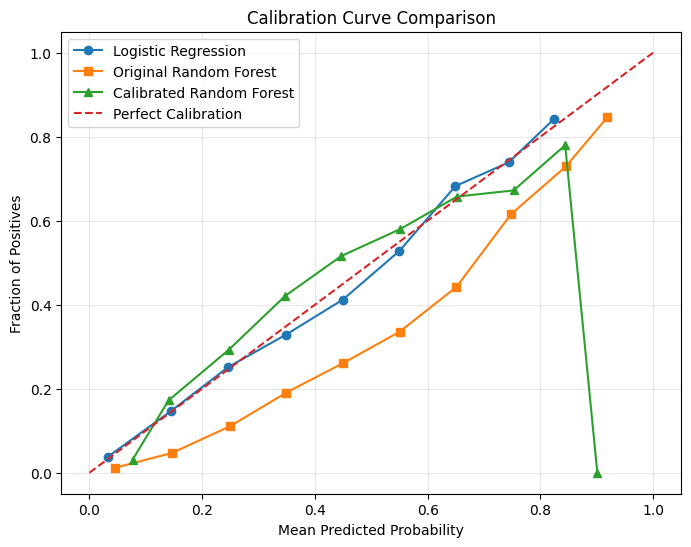

In [158]:
rf_cal_fraction, rf_cal_mean = calibration_curve(
    y_train,
    y_proba_rf_calibrated_oof,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    lr_mean,
    lr_fraction,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    rf_mean,
    rf_fraction,
    marker="s",
    label="Original Random Forest"
)

plt.plot(
    rf_cal_mean,
    rf_cal_fraction,
    marker="^",
    label="Calibrated Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Inspect calibration bins

The table below shows sample counts, mean predicted probabilities and observed churn rates for probability bins. Bins with very few observations are unstable and should not be overinterpreted. In this experiment, the final high-probability bin contained only one observation, so its observed rate is not a reliable indication of calibration in that region.

In [159]:
def inspect_calibration_bins(y_true, y_prob, n_bins=10):

    bin_edges = np.linspace(0, 1, n_bins + 1)

    bin_indices = np.digitize(
        y_prob,
        bin_edges[1:-1]
    )

    calibration_data = pd.DataFrame({
        "Actual": np.asarray(y_true),
        "Probability": np.asarray(y_prob),
        "Bin": bin_indices
    })

    return calibration_data.groupby("Bin").agg(
        Sample_Count=("Actual", "size"),
        Mean_Predicted_Probability=("Probability", "mean"),
        Actual_Churn_Rate=("Actual", "mean")
    )

In [160]:
rf_calibration_bins = inspect_calibration_bins(
    y_train,
    y_proba_rf_calibrated_oof
)

rf_calibration_bins

,Sample_Count,Mean_Predicted_Probability,Actual_Churn_Rate
Bin,,,
0,1975,0.076436,0.030886
1,1272,0.140276,0.172170
2,605,0.247062,0.292562
3,463,0.347352,0.421166
4,310,0.447053,0.516129
5,288,0.551071,0.579861
6,257,0.652235,0.657588
7,244,0.752515,0.672131
8,218,0.844015,0.779817


## 13. Compare candidate models using common outer folds

We now generate out-of-fold predictions for Logistic Regression, the tuned Random Forest and the calibrated Random Forest on the same outer folds. Using common validation partitions makes their predictions directly comparable.

**Methodological limitation:** the Random Forest hyperparameters were selected by a search over the full training set before this outer-fold comparison. Consequently, this comparison is useful for comparing the candidate predictions on common folds, but it is not a fully unbiased nested estimate of the entire hyperparameter-selection procedure. A fully nested evaluation would repeat hyperparameter search inside every outer training fold.

The test set remains untouched and provides our final independent evaluation.

In [161]:
y_proba_lr_outer = np.zeros(len(y_train))
y_proba_rf_outer = np.zeros(len(y_train))
y_proba_rf_calibrated_outer = np.zeros(len(y_train))

In [162]:
from sklearn.base import clone

for fold, (train_idx, val_idx) in enumerate(outer_splits, start=1):

    # Outer training and validation partitions
    X_outer_train = X_train.iloc[train_idx]
    X_outer_val = X_train.iloc[val_idx]

    y_outer_train = y_train.iloc[train_idx]
    groups_outer_train = groups_train.iloc[train_idx]

    # Generate inner group-aware calibration folds
    inner_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    inner_splits = list(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=groups_outer_train
        )
    )

    # 1. Logistic Regression
    lr_model = train.build_model_pipeline()

    lr_model.fit(X_outer_train, y_outer_train)

    y_proba_lr_outer[val_idx] = (
        lr_model.predict_proba(X_outer_val)[:, 1]
    )

    # 2. Original tuned Random Forest
    rf_model = clone(rf_search.best_estimator_)

    rf_model.fit(X_outer_train, y_outer_train)

    y_proba_rf_outer[val_idx] = (
        rf_model.predict_proba(X_outer_val)[:, 1]
    )

    # 3. Calibrated Random Forest
    calibrated_model = train.build_calibrated_rf_pipeline(
        calibration_splits=inner_splits
    )

    calibrated_model.fit(X_outer_train, y_outer_train)

    y_proba_rf_calibrated_outer[val_idx] = (
        calibrated_model.predict_proba(X_outer_val)[:, 1]
    )

    print(f"Completed outer fold {fold}")

Completed outer fold 1
Completed outer fold 2
Completed outer fold 3
Completed outer fold 4
Completed outer fold 5


In [163]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

models = {
    "Logistic Regression": y_proba_lr_outer,
    "Original Random Forest": y_proba_rf_outer,
    "Calibrated Random Forest": y_proba_rf_calibrated_outer
}

comparison_results = []

for model_name, y_proba in models.items():

    y_pred = (y_proba >= 0.5).astype(int)

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_train, y_pred),
        "Precision": precision_score(y_train, y_pred),
        "Recall": recall_score(y_train, y_pred),
        "F1": f1_score(y_train, y_pred),
        "ROC-AUC": roc_auc_score(y_train, y_proba),
        "Average Precision": average_precision_score(y_train, y_proba),
        "Brier Score": brier_score_loss(y_train, y_proba)
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier Score
0,Logistic Regression,0.8115,0.6608,0.5823,0.6191,0.8564,0.6622,0.1308
1,Original Random Forest,0.7779,0.5564,0.7692,0.6457,0.8600,0.6676,0.1486
2,Calibrated Random Forest,0.7958,0.6647,0.4521,0.5382,0.8428,0.6292,0.1391


### Interpretation of the common-fold comparison

The common-fold comparison gave approximately:

| Model | F1 | ROC-AUC | Average Precision | Brier |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.6191 | 0.8564 | 0.6622 | 0.1308 |
| Tuned Random Forest | 0.6457 | 0.8600 | 0.6676 | 0.1486 |
| Calibrated Random Forest | 0.5382 | 0.8428 | 0.6292 | 0.1391 |

At threshold 0.5, the tuned Random Forest has the highest F1 and slightly stronger ranking metrics. Logistic Regression has the lowest Brier score. Calibration changes probability behaviour and therefore also changes the precision/recall balance at a fixed threshold.

The tuned Random Forest is retained as the primary candidate because F1 is our chosen development criterion, with ROC-AUC and AP as supporting ranking metrics. Logistic Regression remains a useful, interpretable baseline.

### Threshold analysis for calibrated Random Forest

We also inspect thresholds for the calibrated model. This illustrates that calibration and threshold selection are related but distinct: calibration changes the probability estimates, while the threshold determines the class decision. We do not select the calibrated model merely because its probabilities are calibrated.

In [164]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

calibrated_threshold_results = []

for threshold in thresholds:

    y_pred = (
        y_proba_rf_calibrated_outer >= threshold
    ).astype(int)

    calibrated_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, y_pred),
        "Recall": recall_score(y_train, y_pred),
        "F1": f1_score(y_train, y_pred)
    })

pd.DataFrame(calibrated_threshold_results).round(4)

,Threshold,Precision,Recall,F1
0,0.2,0.5038,0.8111,0.6215
1,0.3,0.5755,0.6916,0.6283
2,0.4,0.6297,0.5601,0.5929
3,0.5,0.6647,0.4521,0.5382
4,0.6,0.6986,0.3394,0.4569
5,0.7,0.7214,0.2254,0.3434
6,0.8,0.7763,0.1147,0.1999


## 14. Provisional model and threshold decision

Our provisional selection is:

- **Model:** tuned Random Forest.
- **Classification threshold:** 0.5.
- **Primary selection criterion:** F1-score.
- **Supporting metrics:** ROC-AUC and Average Precision.

At threshold 0.5, the tuned Random Forest achieved an out-of-fold F1-score of approximately 0.6457, the highest among the thresholds evaluated for that model.

This is a defensible model-development decision, but 0.5 is **not claimed to be the economically optimal business threshold**. The optimal operating threshold depends on the cost of false positives, the cost of missed churners, retention-campaign effectiveness and team capacity. Those business inputs are not available in the dataset.

The threshold is therefore documented as provisional. We do not use the test set to search for a better threshold.

## 15. Final evaluation on the untouched test set

`RandomizedSearchCV` refitted its best estimator on the full training set. We use that fitted pipeline as `final_model`.

We now predict churn probabilities for `X_test` and apply the preselected threshold of 0.5. This is the first and final evaluation of the selected model on the held-out test set.

After examining these results, we should not tune the model or threshold against the test set. Doing so would compromise its role as an independent estimate of generalization.

In [165]:
final_model = rf_search.best_estimator_

In [166]:
y_test_proba = final_model.predict_proba(X_test)[:, 1]

In [167]:
y_test_pred = (
    y_test_proba >= 0.5
).astype(int)

In [168]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba))
print("Average Precision:", average_precision_score(y_test, y_test_proba))
print("Brier Score:", brier_score_loss(y_test, y_test_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Accuracy: 0.7730496453900709
Precision: 0.5658153241650294
Recall: 0.7441860465116279
F1: 0.6428571428571429
ROC-AUC: 0.8600748672016489
Average Precision: 0.7018800918672601
Brier Score: 0.14663288288730222

Confusion Matrix:
[[802 221]
 [ 99 288]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.78      0.83      1023
           1       0.57      0.74      0.64       387

    accuracy                           0.77      1410
   macro avg       0.73      0.76      0.74      1410
weighted avg       0.80      0.77      0.78      1410



### Test-set results and interpretation

The held-out test results were:

| Metric | Test result |
|---|---:|
| Accuracy | 0.7730 |
| Precision | 0.5658 |
| Recall | 0.7442 |
| F1-score | 0.6429 |
| ROC-AUC | 0.8601 |
| Average Precision | 0.7019 |
| Brier score | 0.1466 |

Confusion matrix:

\[
\begin{bmatrix}
802 & 221 \\
99 & 288
\end{bmatrix}
\]

There are 802 true negatives, 221 false positives, 99 false negatives and 288 true positives.

Recall of 0.7442 means the model identifies 288 of the 387 actual churners in the test set. Precision of 0.5658 means that 56.58% of customers flagged as churners actually churned; the remaining flagged customers are false positives.

The test F1-score (0.6429) is close to the training cross-validation F1 (approximately 0.6457), and test ROC-AUC (0.8601) is close to the cross-validation estimate (approximately 0.8600). This is encouraging and does not indicate an obvious severe generalization gap.

The Brier score is not especially low, so we should not describe the probability estimates as perfectly calibrated. The acceptable false-positive rate depends on the cost and effectiveness of retention interventions.

## 16. Model interpretation with permutation feature importance

Permutation importance measures how much a fitted model's chosen evaluation score deteriorates when one feature is randomly shuffled.

Here we use ROC-AUC on the held-out test set. For each original feature, its values are shuffled across customers and the change in ROC-AUC is measured repeatedly.

- A larger positive importance means the model relies more on that feature for ranking churners.
- An importance near zero suggests little detectable reliance under this test-set evaluation.
- A small negative value can occur from sampling variability; it does not mean the feature causally reduces churn.

We use the original 19 input columns, so the results are easier to interpret than one-hot encoded feature-level importance.

In [169]:
from sklearn.inspection import permutation_importance

In [170]:
perm_importance = permutation_importance(
    estimator=final_model,
    X=X_test,
    y=y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [171]:
feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_importance.importances_mean,
    "Importance_Std": perm_importance.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

feature_importance_df

,Feature,Importance_Mean,Importance_Std
0,Contract,0.045252,0.007227
1,Dependents,0.028762,0.005421
2,Tenure Months,0.019411,0.002204
3,Internet Service,0.017491,0.002783
4,Total Charges,0.009179,0.001268
5,Tech Support,0.004587,0.001283
6,Online Security,0.003245,0.001477
7,Payment Method,0.003241,0.000879
8,Monthly Charges,0.002583,0.000899
9,Streaming TV,0.001914,0.000813


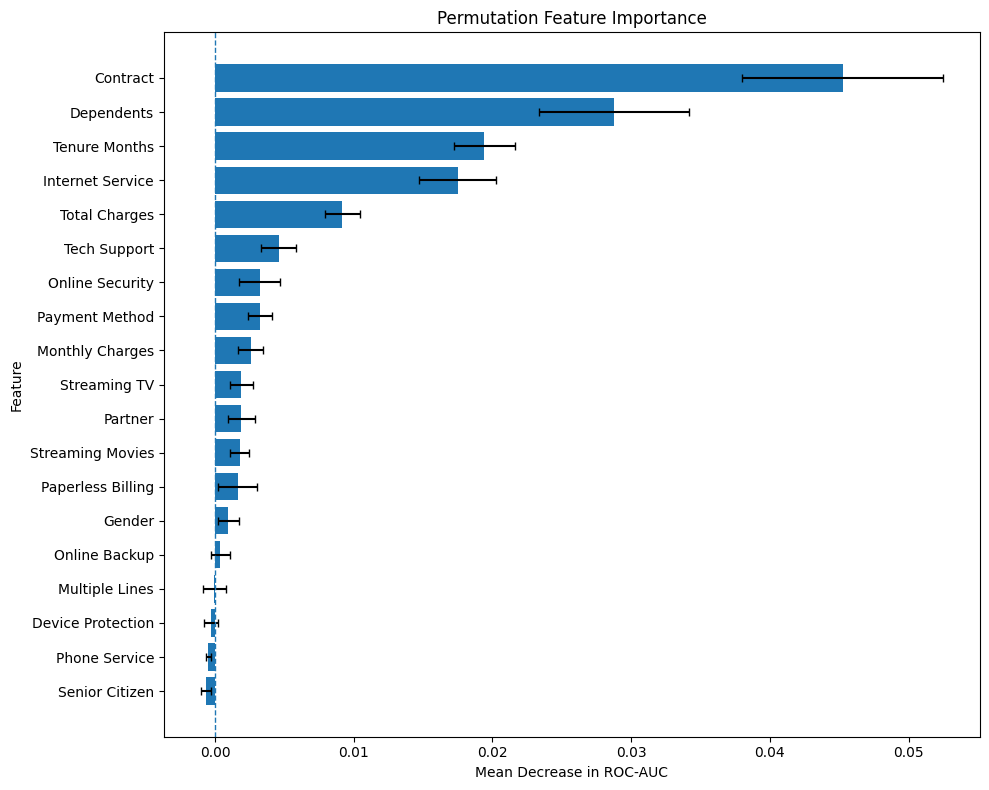

In [172]:
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance_Mean"],
    xerr=feature_importance_df["Importance_Std"],
    capsize=3
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Permutation importance observations

The leading features were Contract (approximately 0.0453), Dependents (0.0288), Tenure Months (0.0194), Internet Service (0.0175) and Total Charges (0.0092).

This ranking is consistent with several patterns observed during EDA. It describes model reliance, not causality. Total Charges and Tenure Months are strongly correlated (approximately 0.826), so their predictive information may be shared between them.

Features with importance close to zero should not be described as having a negative causal effect. Their small negative estimates mean that shuffling slightly improved test ROC-AUC in those repetitions, which can happen through sampling variation.

## 17. Model interpretation with SHAP

SHAP (SHapley Additive exPlanations) attributes a model prediction to its input features. Unlike permutation importance, which measures the effect of shuffling a feature on an overall score, SHAP provides contributions for individual predictions and can be aggregated for a global view.

For this pipeline, we separate:
- the fitted `ColumnTransformer`, which converts the original 19 columns into 46 numeric columns;
- the fitted Random Forest classifier, which operates on those 46 transformed columns.

We use `TreeExplainer`, which is designed for tree-based models. In this notebook's SHAP 0.49.1 output, binary classification SHAP values have shape `(samples, features, classes)`. We select class 1, the churn class.

**Interpretation caution:** SHAP explains the model's predictions. It does not establish that a feature causes customer churn.

In [173]:
preprocessor = final_model.named_steps["preprocessor"]
rf_model = final_model.named_steps["classifier"]

print(type(preprocessor))
print(type(rf_model))
print(rf_model.n_estimators)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'sklearn.ensemble._forest.RandomForestClassifier'>
424


In [174]:
import shap
print(shap.__version__)

0.49.1


In [175]:
explainer = shap.TreeExplainer(rf_model)

### Prepare a representative sample

We explain 100 customers sampled from the held-out test set using a fixed random state for reproducibility. This is a manageable sample for exploration; global SHAP rankings from this sample may vary somewhat with the sample. For a final large-scale analysis, the explanation sample could be increased.

We transform the sample with the already-fitted preprocessor. We call `transform()`, not `fit_transform()`, because the test data must not be used to learn preprocessing parameters.

In [176]:
X_test_sample = X_test.sample(
    n=100,
    random_state=42
)

In [177]:
X_test_sample_processed = preprocessor.transform(
    X_test_sample
)
print(X_test_sample.shape)
print(X_test_sample_processed.shape)

(100, 19)
(100, 46)


In [178]:
shap_values = explainer.shap_values(
    X_test_sample_processed
)

In [179]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(100, 46, 2)


### Select the churn-class SHAP values

The output shape `(100, 46, 2)` represents 100 customers, 46 transformed features and 2 output classes. Selecting `[:, :, 1]` retains the contribution of each transformed feature to the churn-class probability for every sampled customer. The resulting matrix has shape `(100, 46)`.

In [180]:
shap_values_churn = shap_values[:, :, 1]

print(shap_values_churn.shape)

(100, 46)


### Verify SHAP additivity

For this probability-scale explanation, the expected value plus the sum of feature SHAP values should reconstruct the model's predicted probability for the churn class:

\[
P(	ext{Churn}\mid x)=\phi_0+\sum_{i=1}^{46}\phi_i
\]

The SHAP baseline is the explainer's expected model output under TreeSHAP's default tree-path-dependent reference convention, which uses the training path counts stored in the trees. It is **not** the classification threshold. It is also not automatically equal to the observed dataset churn prevalence.

We verify the identity numerically before interpreting the plots.

In [181]:
y_proba_sample = rf_model.predict_proba(
    X_test_sample_processed
)[:, 1]

In [182]:
print(explainer.expected_value)

[0.5 0.5]


In [183]:
base_value = explainer.expected_value[1]

In [184]:
shap_reconstructed = (
    base_value + shap_values_churn.sum(axis=1)
)

print("Actual probabilities:")
print(y_proba_sample[:5])

print("\nSHAP reconstructed probabilities:")
print(shap_reconstructed[:5])

Actual probabilities:
[0.9389322  0.16997375 0.43019524 0.64614745 0.23891927]

SHAP reconstructed probabilities:
[0.9389322  0.16997375 0.43019524 0.64614745 0.23891927]


In [185]:
print(
    "Maximum absolute difference:",
    np.max(np.abs(y_proba_sample - shap_reconstructed))
)

Maximum absolute difference: 8.548717289613705e-15


The maximum absolute difference was approximately \(8.55\times10^{-15}\), effectively zero at floating-point precision. This confirms that the selected class-1 SHAP values reconstruct the Random Forest's churn probabilities for the sampled customers.

In this fitted explainer, the baseline was approximately 0.5. This value is not 0.5 because of the classification threshold; changing the threshold would not change the explainer's baseline.

### Global SHAP summary plot

The beeswarm summary plot displays one dot per customer and transformed feature:

- The horizontal position is the SHAP contribution.
- Positive values push the prediction towards churn; negative values push it away from churn.
- Colour represents the feature value (low to high). For one-hot encoded indicators, high generally means the category is present (1) and low means absent (0).
- Features are ordered by mean absolute SHAP value.

Because categorical columns were one-hot encoded, one original feature can appear as several separate rows, such as the three contract categories.

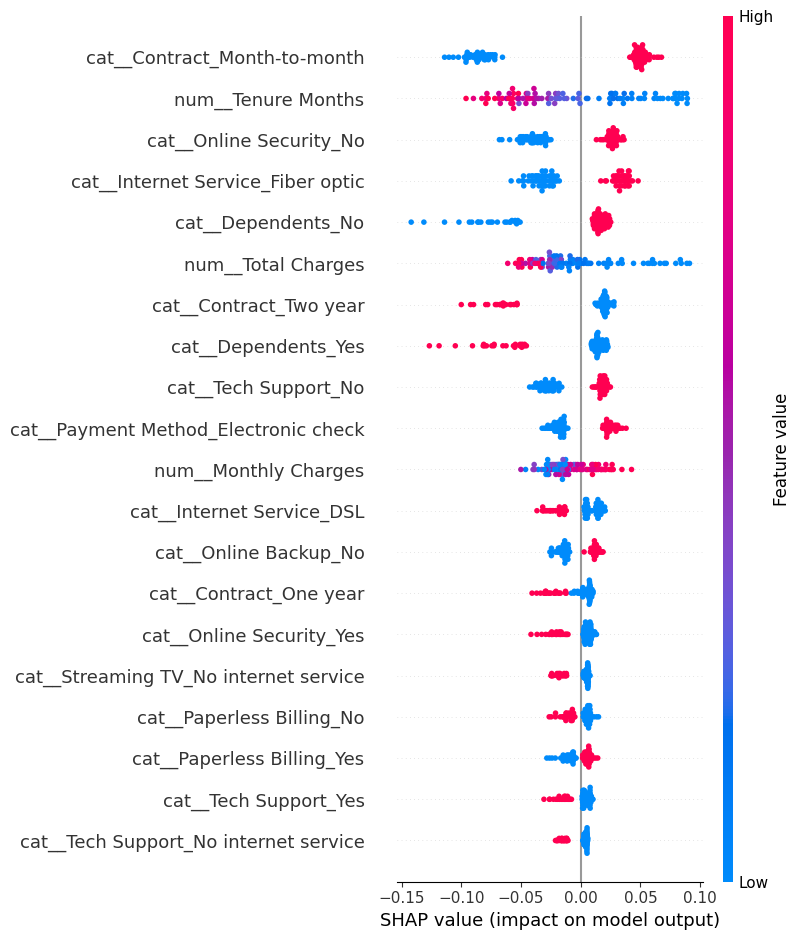

In [186]:
shap.summary_plot(
    shap_values_churn,
    X_test_sample_processed,
    feature_names=preprocessor.get_feature_names_out()
)

### Global SHAP bar plot

The bar plot ranks transformed features by mean absolute SHAP value:

\[
\text{Mean }|\text{SHAP}_i|
=\frac{1}{N}\sum_{j=1}^{N}|\phi_{ij}|
\]

It measures the average magnitude of a feature's contribution, without showing whether the contribution is positive or negative. Since encoded categories appear separately, this ranking is not directly identical to the permutation-importance ranking over the original 19 columns.

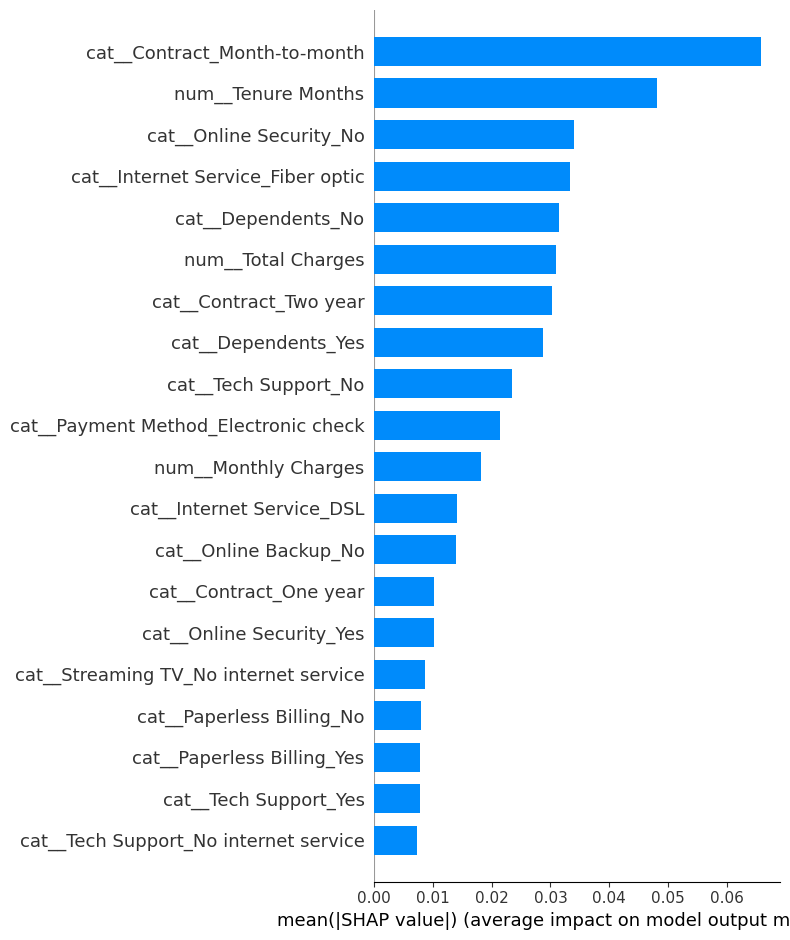

In [187]:
shap.summary_plot(
    shap_values_churn,
    X_test_sample_processed,
    feature_names=preprocessor.get_feature_names_out(),
    plot_type="bar"
)

### Explain one individual customer

We select the first customer in the 100-row explanation sample. The raw customer record is displayed first so that the encoded feature contributions can later be related back to understandable customer attributes.

In [188]:
customer_idx = 0

customer = X_test_sample.iloc[customer_idx]

print(customer)

Gender                           Male
Senior Citizen                     No
Partner                            No
Dependents                         No
Tenure Months                       1
Phone Service                     Yes
Multiple Lines                    Yes
Internet Service          Fiber optic
Online Security                    No
Online Backup                      No
Device Protection                 Yes
Tech Support                       No
Streaming TV                      Yes
Streaming Movies                  Yes
Contract               Month-to-month
Paperless Billing                 Yes
Payment Method       Electronic check
Monthly Charges                101.45
Total Charges                  101.45
Name: 1707, dtype: object


In [189]:
customer_processed = X_test_sample_processed[
    customer_idx:customer_idx + 1
]

customer_probability = rf_model.predict_proba(
    customer_processed
)[0, 1]

print("Predicted churn probability:", customer_probability)

Predicted churn probability: 0.9389322007991998


In [190]:
customer_shap_values = shap_values_churn[customer_idx]

print("Baseline:", base_value)
print("Sum of SHAP values:", customer_shap_values.sum())
print("Reconstructed probability:",
      base_value + customer_shap_values.sum())

Baseline: 0.500000000000003
Sum of SHAP values: 0.4389322007992039
Reconstructed probability: 0.9389322007992069


### SHAP waterfall plot

The waterfall plot starts at the baseline prediction and adds the individual feature contributions until it reaches the model's prediction for this customer.

- Red bars push the churn probability higher.
- Blue bars push it lower.
- The largest bars have the strongest local contributions.
- Features not individually displayed are grouped into an "other features" contribution.

A positive SHAP value is not a causal effect or a percentage of responsibility. It is a contribution to this model's output for this particular customer, given the SHAP attribution procedure.

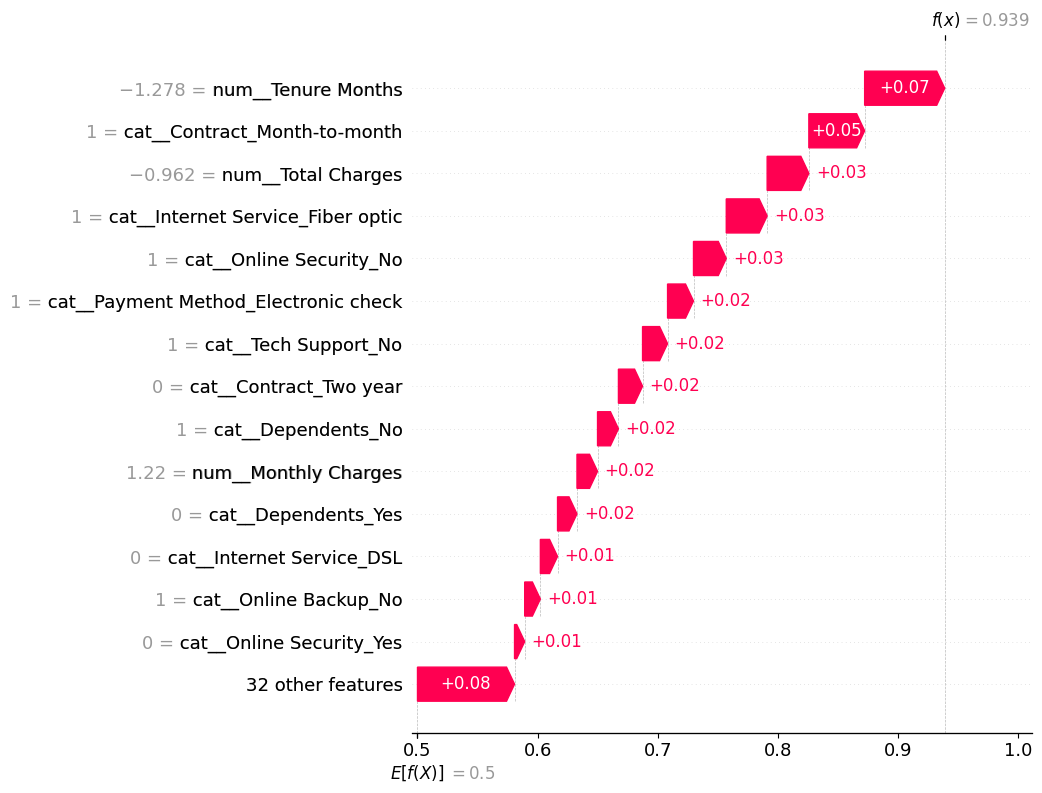

In [191]:
shap.waterfall_plot(
    shap.Explanation(
        values=customer_shap_values,
        base_values=base_value,
        data=X_test_sample_processed[customer_idx],
        feature_names=preprocessor.get_feature_names_out()
    ),
    max_display=15
)

## 18. Overall conclusions and hand-off

This notebook has prepared the customer-level modelling data, established a group-aware train/test split, compared Logistic Regression and Random Forest, tuned the Random Forest, evaluated ranking and calibration, selected a provisional model/threshold, and interpreted the final model.

### Decisions made

- Retained 19 predictors and `Churn Value` as the target.
- Converted the 11 blank `Total Charges` entries associated with zero tenure to 0.0, under the documented assumption.
- Kept repeated customer profiles but grouped them during splitting and cross-validation.
- Used training-only fitted preprocessing inside model pipelines.
- Selected the tuned Random Forest as the primary candidate.
- Retained 0.5 as a provisional threshold based on the highest F1 among tested thresholds for that model.
- Evaluated once on the untouched test set.
- Used permutation importance and SHAP for model interpretation, without treating either as causal analysis.

### Remaining limitations and next work

- The operating threshold should eventually be optimized using retention-campaign costs, missed-churn costs, intervention effectiveness and campaign capacity.
- Probability calibration is imperfect and should be monitored if predicted probabilities are used for business decisions.
- The common-fold comparison of tuned models is not a fully nested estimate because hyperparameter selection preceded the outer-fold comparison.
- SHAP global plots were generated from a 100-customer sample and from one-hot encoded features.
- The project should next persist the complete fitted pipeline, create a reusable inference module, expose predictions through an API, and build an interactive retention dashboard.

In [192]:
import joblib
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
MODEL_PATH = ARTIFACTS_DIR / "churn_random_forest.joblib"

joblib.dump(
    final_model,
    MODEL_PATH
)

print("Model saved successfully!")
print("Location:", MODEL_PATH)

Model saved successfully!
Location: d:\ML_Projects\Project1\customer-churn-intelligence\artifacts\churn_random_forest.joblib


In [193]:
loaded_model = joblib.load(MODEL_PATH)

y_proba_original = final_model.predict_proba(X_test)[:, 1]
y_proba_loaded = loaded_model.predict_proba(X_test)[:, 1]

print(
    "Predictions identical:",
    np.allclose(y_proba_original, y_proba_loaded)
)

Predictions identical: True


In [210]:
from src.models.predict import load_model

loaded_model = load_model()

print(type(loaded_model))

<class 'sklearn.pipeline.Pipeline'>


In [195]:
from src.models.predict import predict_churn

In [196]:
customer_data = X_test_sample.iloc[[0]].copy()

prediction = predict_churn(
    model=loaded_model,
    customer_data=customer_data
)

print(prediction)

   Churn_Probability  Churn_Prediction
0           0.938932                 1


#### Test 1: Missing feature

In [197]:
customer_missing = customer_data.drop(
    columns=["Tenure Months"]
)

try:
    predict_churn(
        loaded_model,
        customer_missing
    )
except ValueError as e:
    print(e)

Missing features: ['Tenure Months']


#### Test 2: Unexpected Feature

In [198]:
customer_extra = customer_data.copy()

customer_extra["CustomerID"] = "TEST001"

try:
    predict_churn(
        loaded_model,
        customer_extra
    )
except ValueError as e:
    print(e)

Unexpected features: ['CustomerID']


Why are we testing incorrect inputs?
This is called negative testing.

Instead of checking only whether our function works with valid inputs, we're checking whether it handles invalid inputs correctly.

A professional prediction system should fail with a clear, meaningful error rather than pass incorrect data to the model.

#### Test 3: Validate missing values

A customer record might contain all 19 expected columns but still have missing values. Our current function would allow those values through.

In [199]:
customer_missing_value = customer_data.copy()

customer_missing_value.loc[
    customer_missing_value.index[0],
    "Tenure Months"
] = np.nan

try:
    predict_churn(loaded_model, customer_missing_value)
except Exception as e:
    print(type(e).__name__, ":", e)

ValueError : Missing values detected in features: ['Tenure Months']


No exception was raised. That means the missing value passed through the preprocessing pipeline and the model still produced a prediction.

Our training dataset had no missing values in the 19 selected features. Therefore, we haven't established that predictions with missing inputs are reliable. We should explicitly reject missing values for now.

In [203]:
result = predict_churn(
    loaded_model,
    customer_missing_value
)

display(result)

ValueError: Missing values detected in features: ['Tenure Months']

#### Test to check whether the features with invalid datatypes are being converted successfully

In [ ]:
customer_string = customer_data.copy()

customer_string["Tenure Months"] = (
    customer_string["Tenure Months"].astype(str)
)

result = predict_churn(
    loaded_model,
    customer_string
)

display(result)

,Churn_Probability,Churn_Prediction
0,0.938932,1


#### Test invalid numerical input

In [ ]:
customer_invalid = customer_data.copy()

customer_invalid["Tenure Months"] = "twelve"

predict_churn(
    loaded_model,
    customer_invalid
)

ValueError: could not convert string to float: 'twelve'

#### Inspect the categories learned during training

In [212]:
from src.data.preprocess import CATEGORICAL_FEATURES

preprocessor = loaded_model.named_steps["preprocessor"]

encoder = (
    preprocessor
    .named_transformers_["cat"]
    .named_steps["encoder"]
)

for feature, categories in zip(
    CATEGORICAL_FEATURES,
    encoder.categories_
):
    print(f"{feature}: {categories}")

Gender: ['Female' 'Male']
Senior Citizen: ['No' 'Yes']
Partner: ['No' 'Yes']
Dependents: ['No' 'Yes']
Phone Service: ['No' 'Yes']
Multiple Lines: ['No' 'No phone service' 'Yes']
Internet Service: ['DSL' 'Fiber optic' 'No']
Online Security: ['No' 'No internet service' 'Yes']
Online Backup: ['No' 'No internet service' 'Yes']
Device Protection: ['No' 'No internet service' 'Yes']
Tech Support: ['No' 'No internet service' 'Yes']
Streaming TV: ['No' 'No internet service' 'Yes']
Streaming Movies: ['No' 'No internet service' 'Yes']
Contract: ['Month-to-month' 'One year' 'Two year']
Paperless Billing: ['No' 'Yes']
Payment Method: ['Bank transfer (automatic)' 'Credit card (automatic)' 'Electronic check'
 'Mailed check']


In [214]:
customer_invalid_category = customer_data.copy()

customer_invalid_category["Contract"] = "Quarterly"

In [215]:
for feature in CATEGORICAL_FEATURES:

    valid_categories = encoder.categories_[
        CATEGORICAL_FEATURES.index(feature)
    ]

    supplied_categories = (
        customer_invalid_category[feature].unique()
    )

    invalid_categories = set(supplied_categories) - set(valid_categories)

    if invalid_categories:
        print(feature, ":", invalid_categories)

Contract : {'Quarterly'}


In [217]:
import importlib
import src.models.predict as predict

importlib.reload(predict)

predict.predict_churn(
    loaded_model,
    customer_invalid_category
)

ValueError: Invalid categories in 'Contract': ['Quarterly']. Expected one of: ['Month-to-month', 'One year', 'Two year']

In [218]:
result = predict.predict_churn(
    loaded_model,
    customer_data
)

display(result)

,Churn_Probability,Churn_Prediction
0,0.938932,1


#### Test to handle whitespace

In [ ]:
## testing before making changes in predict.py to handle this
customer_whitespace = customer_data.copy()

customer_whitespace["Contract"] = (
    customer_whitespace["Contract"] + " "
)

result = predict.predict_churn(
    loaded_model,
    customer_whitespace
)

ValueError: Invalid categories in 'Contract': ['Month-to-month ']. Expected one of: ['Month-to-month', 'One year', 'Two year']

In [220]:
## testing after making changes in predict.py to handle this
result = predict.predict_churn(
    loaded_model,
    customer_whitespace
)

display(result)

,Churn_Probability,Churn_Prediction
0,0.938932,1


#### Test to handle capitalisation

In [221]:
customer_lowercase = customer_data.copy()

customer_lowercase["Gender"] = "female"

In [222]:
predict.predict_churn(
    loaded_model,
    customer_lowercase
)

ValueError: Invalid categories in 'Gender': ['female']. Expected one of: ['Female', 'Male']

In [ ]:
### Test to check whether there are any duplicate columns

In [ ]:
customer_duplicate = customer_data.copy()

customer_duplicate["Gender_duplicate"] = (
    customer_duplicate["Gender"]
)

customer_duplicate = customer_duplicate.rename(
    columns={"Gender_duplicate": "Gender"}
)

print(customer_duplicate.columns.duplicated().any())

True


In [ ]:
## After making changes in predict.py to handle duplicate features
predict.predict_churn(
    loaded_model,
    customer_duplicate
)

ValueError: Duplicate column names detected: ['Gender']